# 04. Let the screen remember

Use state, immutable updates, reducers, and context without creating competing copies of the same fact.

**55 minutes including practice · Roots**

This is a **Python 3 notebook**. It contains the complete lesson, embedded vector illustrations, React Native examples for reading, and executable Python models. Python does not run React Native. Run the `.tsx` exercise in Expo using the workbook instructions. No cloud credentials or live services are needed for the notebook.

Run the cells from top to bottom. Change a control, make a prediction, then explain the result. If widgets are unavailable, edit a model's default arguments and rerun its cell.

If you have the complete course folder, [open the interactive guide](../index.html#lesson-04) or [read the exercise instructions](../exercises/README.md). These companion links are absent in a notebooks-only or single-lesson download; the notebook itself still runs independently.


## What you will be able to do

- You can predict the result of repeated state updates in one event.
- You can update one item in an array without changing the previous array.
- You can choose local state, lifted state, context, or a reducer for a concrete job.

## Before you begin

You can build a component from props and call an event callback.

You can follow map and filter on JavaScript arrays.


In [1]:
from IPython.display import display, HTML, SVG
import json
import os
import inspect

# Widgets are optional. Without them, edit parameters and rerun the model cell.
try:
    if os.environ.get('PLANTOPEDIA_NO_WIDGETS') == '1':
        raise ImportError('Widget-free verification mode')
    import ipywidgets as widgets
except ImportError:
    widgets = None

def explore(function, **controls):
    if widgets is not None:
        display(widgets.interactive(function, **controls))
    else:
        print('Optional controls are unavailable. Edit the explorer function defaults and rerun this model cell.')
        defaults = {name: parameter.default for name, parameter in inspect.signature(function).parameters.items()}
        print('Using function defaults:', defaults)
        function()

print('Python teaching model ready. React Native TSX runs separately in Expo.')


Python teaching model ready. React Native TSX runs separately in Expo.


A plant card becomes interactive when the screen remembers something: whether its menu is open, what the reader has typed, or which photo is selected. A plain local variable does not give React a reliable instruction to display a new result. State connects an event to the next screen description.

The goal is not to place every value in a large global store. The goal is to give each fact a clear owner. Plantopedia uses small local values for screen interaction, context for shared preferences and session services, and TanStack Query for server records. This lesson teaches the first two responsibilities and prepares you to recognize the third.


## A state value belongs to one render

useState returns the value for the current render and a setter that requests an update. The current event handler continues to see that render’s value even after calling the setter. If count is 0, two calls to setCount(count + 1) both request the value 1. They do not make the count variable become 1 between the calls.

When the next value depends on the previous queued value, pass an updater function. Two calls to setCount(previous => previous + 1) produce 2 from 0 because each updater receives the result of the preceding update. The teaching component places the two choices side by side so you can predict the result before pressing either button.

Both methods are useful when their intention is clear. A direct setter can replace a value with a chosen nickname. An updater is useful when building from what is already there. Do not depend on an immediate console log after the setter to show the next render’s state. Read the rendered result or inspect the subsequent render instead.


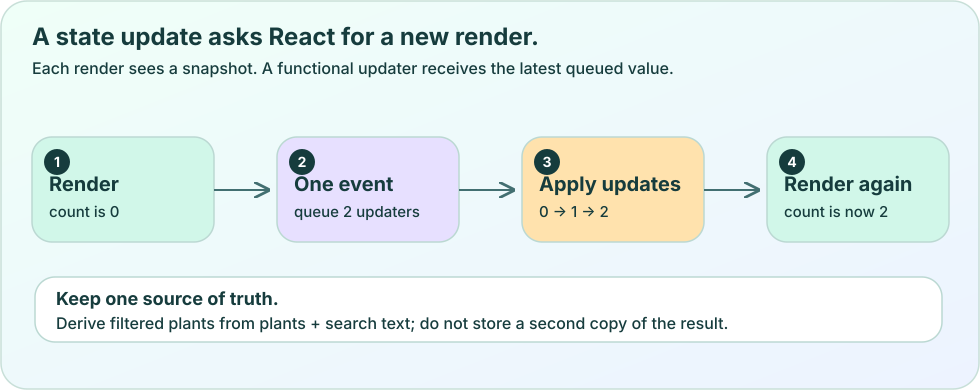

In [2]:
# Embedded original vector illustration; no external image files are required.
display(SVG(data='<svg xmlns="http://www.w3.org/2000/svg" width="980" height="390" viewBox="0 0 980 390" role="img" aria-labelledby="title desc"><title id="title">State snapshots and queued updates</title><desc id="desc">A render sees count zero. Two functional updater calls queue increments, React applies them to obtain two, and the next render displays two. Derive filtered data from the original list.</desc><defs>\n<linearGradient id="bg" x2="1" y2="1"><stop stop-color="#effff8"/><stop offset="1" stop-color="#edf3ff"/></linearGradient>\n<linearGradient id="leaf" x2="1" y2="1"><stop stop-color="#37e6b0"/><stop offset="1" stop-color="#07886c"/></linearGradient>\n<linearGradient id="glass" x2="1" y2="1"><stop stop-color="#fff" stop-opacity=".94"/><stop offset="1" stop-color="#e2efff" stop-opacity=".72"/></linearGradient>\n<linearGradient id="violet" x2="1" y2="1"><stop stop-color="#a58cff"/><stop offset="1" stop-color="#6550d9"/></linearGradient>\n<marker id="arrow" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto"><path d="M0 0L8 4L0 8" fill="none" stroke="#426f71" stroke-width="1.4"/></marker>\n</defs><g font-family="system-ui,-apple-system,Segoe UI,sans-serif"><rect x="1" y="1" width="978" height="388" rx="26" fill="url(#bg)" stroke="#c8dfd8" stroke-width="1.5"/><text x="32" y="45" font-size="24" fill="#163c3d" font-weight="750" text-anchor="start">A state update asks React for a new render.</text><text x="32" y="74" font-size="16" fill="#163c3d" font-weight="500" text-anchor="start">Each render sees a snapshot. A functional updater receives the latest queued value.</text><rect x="32" y="137" width="182" height="105" rx="20" fill="#d1f7e9" stroke="#bbd8d2" stroke-width="1.5"/><circle cx="57" cy="162" r="13" fill="#163c3d"/><text x="57" y="167" font-size="14" fill="#fff" font-weight="700" text-anchor="middle">1</text><text x="49" y="191" font-size="20" fill="#163c3d" font-weight="700" text-anchor="start">Render</text><text x="49" y="217" font-size="15" fill="#163c3d" font-weight="500" text-anchor="start">count is 0</text><rect x="277" y="137" width="182" height="105" rx="20" fill="#e7e0ff" stroke="#bbd8d2" stroke-width="1.5"/><circle cx="302" cy="162" r="13" fill="#163c3d"/><text x="302" y="167" font-size="14" fill="#fff" font-weight="700" text-anchor="middle">2</text><text x="294" y="191" font-size="20" fill="#163c3d" font-weight="700" text-anchor="start">One event</text><text x="294" y="217" font-size="15" fill="#163c3d" font-weight="500" text-anchor="start">queue 2 updaters</text><rect x="522" y="137" width="182" height="105" rx="20" fill="#ffe2ad" stroke="#bbd8d2" stroke-width="1.5"/><circle cx="547" cy="162" r="13" fill="#163c3d"/><text x="547" y="167" font-size="14" fill="#fff" font-weight="700" text-anchor="middle">3</text><text x="539" y="191" font-size="20" fill="#163c3d" font-weight="700" text-anchor="start">Apply updates</text><text x="539" y="217" font-size="15" fill="#163c3d" font-weight="500" text-anchor="start">0 → 1 → 2</text><rect x="767" y="137" width="182" height="105" rx="20" fill="#d1f7e9" stroke="#bbd8d2" stroke-width="1.5"/><circle cx="792" cy="162" r="13" fill="#163c3d"/><text x="792" y="167" font-size="14" fill="#fff" font-weight="700" text-anchor="middle">4</text><text x="784" y="191" font-size="20" fill="#163c3d" font-weight="700" text-anchor="start">Render again</text><text x="784" y="217" font-size="15" fill="#163c3d" font-weight="500" text-anchor="start">count is now 2</text><path d="M214 190L268 190" stroke="#426f71" stroke-width="2" fill="none" marker-end="url(#arrow)"/><path d="M459 190L513 190" stroke="#426f71" stroke-width="2" fill="none" marker-end="url(#arrow)"/><path d="M704 190L758 190" stroke="#426f71" stroke-width="2" fill="none" marker-end="url(#arrow)"/><rect x="35" y="277" width="907" height="65" rx="20" fill="#fff" stroke="#bbd8d2" stroke-width="1.5"/><text x="56" y="305" font-size="18" fill="#163c3d" font-weight="700" text-anchor="start">Keep one source of truth.</text><text x="56" y="329" font-size="16" fill="#163c3d" font-weight="500" text-anchor="start">Derive filtered plants from plants + search text; do not store a second copy of the result.</text></g></svg>'))


**Teaching component: SnapshotCounter.tsx**

Read this example here; TSX runs in Expo, while shell commands run in a terminal. This notebook uses a Python kernel.

```tsx
import { useState } from "react";
import { Button, Text, View } from "react-native";

export default function SnapshotCounter() {
  const [count, setCount] = useState(0);
  return (
    <View style={{ padding: 24, gap: 16 }}>
      <Text accessibilityLiveRegion="polite">Count: {count}</Text>
      <Button title="Queue two replacements" onPress={() => {
        setCount(count + 1);
        setCount(count + 1);
      }} />
      <Button title="Queue two updaters" onPress={() => {
        setCount(previous => previous + 1);
        setCount(previous => previous + 1);
      }} />
      <Button title="Reset" onPress={() => setCount(0)} />
    </View>
  );
}
```


## Keep one source for the fact you already know

Suppose a note editor stores text and also stores an isBlank boolean. Every edit must update both values correctly. Instead, keep the text and calculate text.trim().length === 0 while rendering. The blank condition follows automatically from the value it describes.

The same principle applies to a selected plant. If you have a list and a selected ID, you can find the selected record from those values. Keeping a second, independently edited copy of the whole plant invites disagreement. One copy might have a new nickname while the other still has the old one.

Plantopedia’s profile screen keeps local note text, disclosure state, and a selected photo ID. These represent reader interaction. The loaded plant detail belongs to its query. Copying every server record into useState would force the screen to invent its own rules for refreshing, errors, and account changes. We will let the query own that work in the next lesson.


## Create a new array for a new result

Treat an array already held in state as the previous description of the data. To rename one item, use map to return a new array and a new object for the changed item. To remove an item, use filter. Reading an existing object is fine; changing its nickname directly would also change the old object that other parts of the code may still reference.

A shallow array copy alone does not copy every object inside it. Writing const next = [...plants] and then changing next[0].nickname still changes the original first object. The teaching reducer below uses an object spread only for the matched record. The other records can keep their existing references because their data has not changed.

An immutable update makes the transition easier to explain and test. You can compare the previous array with the next array and still inspect what the previous record contained. This is especially valuable when two specimens share a name: match the stable ID, so only the intended one changes.


**Teaching logic: plant-summary-reducer.ts**

Read this example here; TSX runs in Expo, while shell commands run in a terminal. This notebook uses a Python kernel.

```ts
export type Summary = { id: string; nickname: string };
export type Action =
  | { type: "rename"; id: string; nickname: string }
  | { type: "remove"; id: string };

export function summariesReducer(
  state: Summary[], action: Action,
): Summary[] {
  switch (action.type) {
    case "rename":
      return state.map(plant => plant.id === action.id
        ? { ...plant, nickname: action.nickname }
        : plant);
    case "remove":
      return state.filter(plant => plant.id !== action.id);
  }
}
```


## A reducer names the transition; context shares access

A reducer is a function that receives the previous state and an action, then returns the next state. The action describes an event such as rename or remove. It is useful when several related handlers need the same transition rules. A reducer should not send a network request, read a token, or write a file while calculating that next state.

Context solves a different problem. A provider makes a value available to descendants without passing it through every intermediate component. It does not automatically decide transition rules, persist data, or authorize access. You can combine a reducer with context, but neither requires the other.

This repository’s PreferencesProvider shares theme, language, translated words, and the setter for preference changes. SessionProvider shares the current owner’s API client and related services. These are separate contexts because their responsibilities differ. A menu that opens only inside one card usually belongs in that card’s local state, not in a provider used by every screen.


**Teaching component using the reducer: SummaryEditor.tsx**

Read this example here; TSX runs in Expo, while shell commands run in a terminal. This notebook uses a Python kernel.

```tsx
import { useReducer } from "react";
import { Button, Text, View } from "react-native";
import { summariesReducer } from "./plant-summary-reducer";

export default function SummaryEditor() {
  const [plants, dispatch] = useReducer(summariesReducer, [
    { id: "east", nickname: "Lemon" },
    { id: "west", nickname: "Lemon" },
  ]);
  return (
    <View style={{ padding: 24, gap: 16 }}>
      {plants.map(plant => <Text key={plant.id}>
        {plant.id}: {plant.nickname}
      </Text>)}
      <Button title="Rename the east tree" onPress={() => dispatch({
        type: "rename", id: "east", nickname: "Balcony lemon",
      })} />
    </View>
  );
}
```


## Place state where the sharing actually happens

If two sibling components both need the same selected photo, move that selected ID to their nearest shared parent and pass the value and callbacks down. This is often called lifting state. The parent becomes the owner, so selecting a thumbnail and displaying its detail cannot silently update unrelated copies.

Keep hooks at the top level of a component or another hook. Do not call useState only when a menu is open or inside a loop over plants. Each card can be its own component with its own top-level hook. This gives each rendered card a stable place for its interaction memory.

Finally, distinguish memory from persistence. useState and a reducer do not keep an unsaved note after the process ends. Context also disappears with the running app. Plantopedia uses storage for records that must survive a restart. Choosing context because a value is important does not make that value durable; storage is an additional responsibility taught in lesson 08.


> **Ask who owns this fact**
>
> Use local state for one screen’s interaction, lift it when siblings share it, use context for widely needed dependencies, and use a reducer when related transitions need explicit rules. None of these choices automatically saves data to disk.


## Experiment: predict, change, explain

Set an initial count, choose replacement or functional updates, and choose how many updates are queued in one event. Defaults are 0, replacement updates, and two updates. Predict the printed next count before changing the controls. Then edit the rename example and inspect the assertions about the previous list and unchanged neighbor. This model explains a bounded state transition; React itself is not running.

The cell below is a bounded Python analogy of the lesson. Its fixtures do not call the app API, request permission, or certify device behavior. Its assertions check the stated model only.


In [3]:
def queued_count(initial, functional, updates=2):
    # Bounded analogy for updates queued in ONE event from ONE render snapshot.
    snapshot, result = initial, initial
    for _ in range(updates):
        result = result + 1 if functional else snapshot + 1
    return result

def explore_state(initial=0, functional=False, updates=2):
    print('Render snapshot:', initial)
    print('Queued update strategy:', 'latest queued value' if functional else 'same render snapshot')
    print('Next render count:', queued_count(initial, functional, updates))

explore(explore_state, initial=(0, 8), functional=False, updates=(0, 4))

def rename(items, identifier, nickname):
    return [{**p, 'nickname': nickname} if p['id'] == identifier else p for p in items]

before = [{'id': 'fern_01', 'nickname': 'Kitchen fern'}, {'id': 'fern_02', 'nickname': 'Patio fern'}]
after = rename(before, 'fern_01', 'Window fern')
assert before[0]['nickname'] == 'Kitchen fern'
assert after[0]['id'] == before[0]['id']
assert after is not before and after[0] is not before[0]
assert after[1] is before[1]
assert queued_count(0, False) == 1
assert queued_count(0, True) == 2
print('Snapshot, identity, and immutable-update checks passed.')


interactive(children=(IntSlider(value=0, description='initial', max=8), Checkbox(value=False, description='fun…

Snapshot, identity, and immutable-update checks passed.


## Make a prediction of your own

Predict the count after THREE functional updates starting at 2.

Replace `None` below. A blank answer reports **not attempted**; it is never counted as passing. The check gives feedback without interrupting “Run All.”


In [4]:
your_answer = None  # Replace with a number, then check your prediction with queued_count.
if your_answer is None:
    print('Not attempted. Replace None, then rerun this cell.')
elif your_answer == 5:
    print('Correct. '+'Each updater receives the previous queued result: 2 → 3 → 4 → 5.')
else:
    print('Revisit your prediction. '+'Each updater receives the previous queued result: 2 → 3 → 4 → 5.')


Not attempted. Replace None, then rerun this cell.


## Retrieve the ideas

**1. count is 0. One handler calls setCount(count + 1) twice. What does the next render show?**

1. 2
2. 1
3. An error because setters can run only once.

**2. You copied an array with [...plants]. Is it safe to change next[0].nickname directly?**

1. Yes, because spread recursively copied every item.
2. Yes, if both plants have the same name.
3. No, because the item object is still shared with the previous array.

**3. Which value most naturally belongs in a card’s local state?**

1. Whether that one card’s options menu is open.
2. A server administrator key.
3. A second independent copy of every query result.

Set each value in the next cell to your selected option number, starting at 1. You can change it and rerun for more feedback.


In [5]:
quiz = [{'question': 'count is 0. One handler calls setCount(count + 1) twice. What does the next render show?', 'options': ['2', '1', 'An error because setters can run only once.'], 'answer': 1, 'explanation': 'Both expressions read count from the same render, so both request 1. Updater functions would each receive the latest queued result and could produce 2.'}, {'question': 'You copied an array with [...plants]. Is it safe to change next[0].nickname directly?', 'options': ['Yes, because spread recursively copied every item.', 'Yes, if both plants have the same name.', 'No, because the item object is still shared with the previous array.'], 'answer': 2, 'explanation': 'The array is new, but its existing item references are reused. Return a new object for the changed item, usually through map, to preserve the previous state.'}, {'question': 'Which value most naturally belongs in a card’s local state?', 'options': ['Whether that one card’s options menu is open.', 'A server administrator key.', 'A second independent copy of every query result.'], 'answer': 0, 'explanation': 'A local menu is an interaction owned by the card. Private credentials belong on the server, and duplicating query data introduces another source that must be kept synchronized.'}]
answers = [None, None, None]  # Replace None with 1, 2, or 3.
correct = 0
for number, (question, answer) in enumerate(zip(quiz, answers), 1):
    if answer is None:
        print(f'{number}. Not attempted.')
    elif type(answer) is not int or answer not in range(1, len(question['options']) + 1):
        print(f'{number}. Choose a valid option number.')
    else:
        right = answer - 1 == question['answer']
        correct += int(right)
        print(f"{number}. {'Correct' if right else 'Revisit this idea'}. {question['explanation']}")
print(f'{correct} of {len(quiz)} correct; unanswered questions do not count as passing.')


1. Not attempted.
2. Not attempted.
3. Not attempted.
0 of 3 correct; unanswered questions do not count as passing.


## Build in Expo: Rename one lemon tree and preserve the other

Implement and explain an immutable rename transition, then connect it to a small reducer-driven screen.

1. Start with two summaries whose nickname is Lemon and whose IDs differ.
2. Predict the two counter results before operating the browser lab or Expo component.
3. Implement rename with map and match by id. Create a new object only for the matched record.
4. Assert in a small logic check that the previous array still contains the original nickname and that the west specimen is unchanged.
5. Connect the reducer to SummaryEditor and explain why dispatch describes an action rather than directly editing a Text node.
6. Write where you would put a shared selected-photo ID and what additional work would make an unsaved note survive a restart.

### Check your result

- [ ] Only the selected ID receives the new name.
- [ ] The previous record object is unchanged.
- [ ] The rendered list uses stable IDs as keys.
- [ ] Your explanation separates local memory, shared access, transition logic, and durable storage.

Download the matching exercise bundle from the HTML course, or use the `exercises` folder if you downloaded the complete course. A notebooks-only download does not include that folder. Files under `docs/tutorials` do not become Expo routes until copied as instructed. The numbered workbook supplies a related concrete practice task; the inline exercise can ask you to extend it.


<details><summary>Hint</summary>

The rename branch should return state.map(...). Its matching branch returns {...plant, nickname: action.nickname}.

</details>

<details><summary>Worked reasoning / solution</summary>

```text
Use the summariesReducer shown above. For a rename of east, next !== previous, next[0] !== previous[0], previous[0].nickname remains Lemon, and next[1] === previous[1] because the west record did not change. Dispatching causes useReducer to calculate a new state and React to render that result. A shared parent can own selectedPhotoId; surviving process termination requires a storage write and restore path.
```

</details>


## Explain it in your own words

A note editor, a photo strip, and a save button need to agree on the selected specimen. Describe a state owner for that identity, and explain why putting it in context alone would not make it survive a restart.

*Write your explanation in the Markdown cell below. Save the notebook to keep your work.*


My explanation:

<!-- Replace this comment with a connected explanation and an example. -->


## Find this idea in the app

- [src/components/PlantCard.tsx](../../../src/components/PlantCard.tsx) — Keeps focus and options-menu interaction in local state.

- [src/app/plants/[plantId].tsx](../../../src/app/plants/[plantId].tsx) — Separates local note and photo selection from queried plant details.

- [src/theme/preferences.tsx](../../../src/theme/preferences.tsx) — Shares theme and language through a provider and restores stored preferences.

- [src/services/session.tsx](../../../src/services/session.tsx) — Shares owner-scoped API and voice services through a session context.

Repository links require this notebook to remain in the checkout’s `docs/tutorials/notebooks` folder. Downloaded notebooks still contain every explanation and embedded diagram.

## Primary documentation

- [State as a snapshot](https://react.dev/learn/state-as-a-snapshot)
- [Queueing state updates](https://react.dev/learn/queueing-a-series-of-state-updates)
- [Updating arrays in state](https://react.dev/learn/updating-arrays-in-state)
- [Reducer and context](https://react.dev/learn/scaling-up-with-reducer-and-context)


## Carry these ideas forward

- State setters schedule a future render; the current handler keeps its snapshot.
- A new array must also contain a new object for an item whose data changes.
- Context shares access, reducers define transitions, and storage provides durability.
